# Detection and Counterfactual on Your Own File

Runs the **two core steps** on a single CGM file — no preprocessing pipeline, no cohort, no `CGM_DATA_ROOT`:

1. **Detection and classification** of hyperglycaemia episodes (> 180 mg/dL) as SLH or LLH with criteria C1–C6.
2. **Counterfactual** signal C(t): what the glucose trace would look like without the SLH episodes.

The same code is available as a command: `make example INPUT=my_patient.csv` (see the README).

> **Illustration only.** This notebook is run on a **synthetic trace** (`demo_trace()`: simulated glucose, time expressed relative to an arbitrary t = 0). It contains **no real patient data**, and the numbers are not expected to match the manuscript.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Make `src` and `scripts` importable whether Jupyter was started from the repo root or from notebooks/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.preprocessing.timestep import detect_dominant_sampling_interval
from src.episodes.detection import detect_hyperglycemia_episodes
from src.episodes.criteria import classify_episodes
from src.episodes.episode_config import H_HYPER, LABEL_SLH
from src.counterfactual.build_counterfactual import build_full_counterfactual_signal
from src.metrics.metrics import compute_time_in_range_metrics
from scripts.examples.detect_and_counterfactual import load_trace, demo_trace, categorise

# the import above selects a file-only backend; switch back to inline figures
%matplotlib inline

## 2. Load the trace

The input is **one patient** with a time column and a glucose column (mg/dL by default). `load_trace` reads CSV, TSV or Excel,
detects the column names, and converts mmol/L with `unit="mmol/L"`. Here the synthetic demo trace is used; to use your own file, set
`CGM_FILE`.

In [2]:
CGM_FILE = None            # e.g. "my_patient.csv"  (columns such as time / glucose; add unit="mmol/L" if needed)

df = load_trace(CGM_FILE) if CGM_FILE else demo_trace()
print(f"{len(df)} readings, {df['time'].min()} -> {df['time'].max()}")
df.head()

864 readings, 2000-01-01 00:00:00 -> 2000-01-03 23:55:00


,time,glycemie
0,2000-01-01 00:00:00,120.000000
1,2000-01-01 00:05:00,120.199917
2,2000-01-01 00:10:00,120.399334
3,2000-01-01 00:15:00,120.597753
4,2000-01-01 00:20:00,120.794677


The code expects a clean, time-sorted trace from a 5-minute CGM. The pipeline's preprocessing (quality flags, 45-day window with
at least 70 % coverage) is **not** applied here.

Sampling interval: 5 min


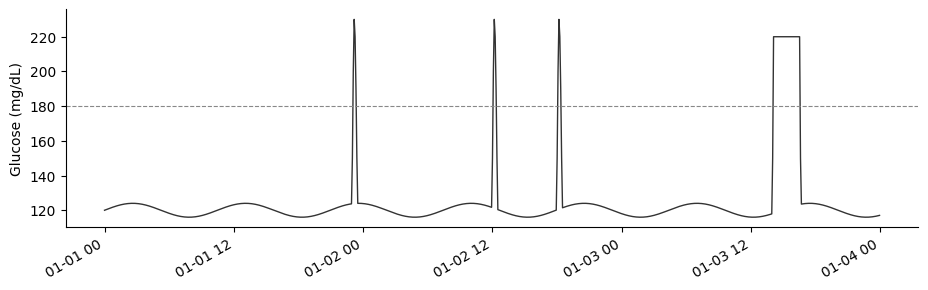

In [3]:
timestep = detect_dominant_sampling_interval(df)
print(f"Sampling interval: {timestep:g} min")

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(df["time"], df["glycemie"], color="#333333", lw=1)
ax.axhline(H_HYPER, color="#888888", ls="--", lw=0.8)
ax.set_ylabel("Glucose (mg/dL)"); ax.spines[["top", "right"]].set_visible(False)
fig.autofmt_xdate(); plt.show()

## 3. Detect and classify the episodes

`detect_hyperglycemia_episodes` returns every run of glucose above 180 mg/dL (close runs are merged).
`classify_episodes` evaluates the six criteria for each episode: C1 duration (10–60 min), C2 data completeness, C3 daytime onset,
C4/C5 no hyperglycaemia before/after, C6 crossing condition. An episode passing all six is **SLH**, otherwise **LLH**.

In [4]:
episodes = detect_hyperglycemia_episodes(df)
table = categorise(classify_episodes(df, episodes))      # adds the Figure 2 "category" column
table[["onset_time", "offset_time", "duration_min", "C1", "C2", "C3", "C4", "C5", "C6", "classification", "category"]]

,onset_time,offset_time,duration_min,C1,C2,C3,C4,C5,C6,classification,category
0,2000-01-01 23:05:00,2000-01-01 23:20:00,20.0,True,True,False,True,True,True,LLH,Night
1,2000-01-02 12:05:00,2000-01-02 12:20:00,20.0,True,True,True,True,True,True,SLH,SLH
2,2000-01-02 18:05:00,2000-01-02 18:20:00,20.0,True,True,True,True,True,True,SLH,SLH
3,2000-01-03 14:05:00,2000-01-03 16:30:00,150.0,False,True,True,True,True,True,LLH,LLH


In [5]:
print(table["category"].value_counts().to_string())

category
SLH      2
Night    1
LLH      1


## 4. Build the counterfactual

The SLH episodes are replaced by a linear interpolation between anchors placed `offset_min` minutes before the onset and after the
offset (zone expansion δ, default 30 min), then smoothed. Everything outside the SLH zones is unchanged.

In [6]:
OFFSET_MIN = 30

slh = table.loc[table["classification"] == LABEL_SLH, ["onset_time", "offset_time"]].to_dict("records")
df["counterfactual"] = build_full_counterfactual_signal(df, slh, OFFSET_MIN, timestep)
print(f"{len(slh)} SLH episode(s); {int((df['counterfactual'] != df['glycemie']).sum())} readings modified")

2 SLH episode(s); 24 readings modified


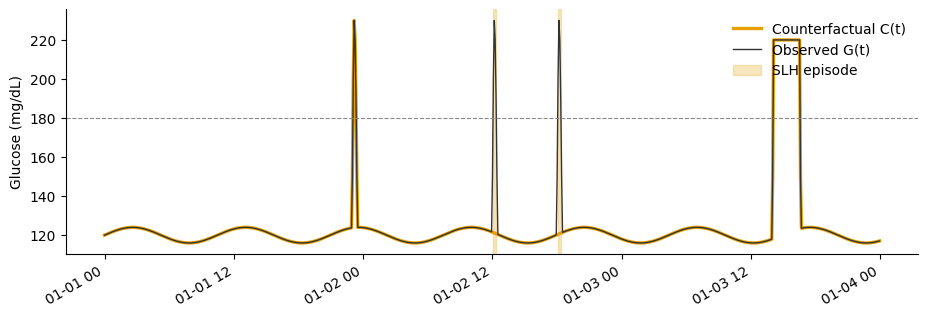

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(df["time"], df["counterfactual"], color="#E69F00", lw=2.4, label="Counterfactual C(t)")
ax.plot(df["time"], df["glycemie"], color="#333333", lw=1, label="Observed G(t)")
for k, ep in enumerate(slh):
    ax.axvspan(ep["onset_time"], ep["offset_time"], color="#E69F00", alpha=0.25, label="SLH episode" if k == 0 else None)
ax.axhline(H_HYPER, color="#888888", ls="--", lw=0.8)
ax.set_ylabel("Glucose (mg/dL)"); ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False); fig.autofmt_xdate(); plt.show()

## 5. Effect on the glucose metrics

The metrics are computed on both signals; the difference Δ = C − G is the contribution of the SLH episodes.

In [8]:
obs_m = compute_time_in_range_metrics(df["glycemie"])
cf_m = compute_time_in_range_metrics(df["counterfactual"])

rows = []
for name, key in [("TIR 70–180 (%)", "TIR70180"), ("TAR > 180 (%)", "TAR180")]:
    rows.append({"metric": name, "observed": 100 * obs_m[key], "counterfactual": 100 * cf_m[key]})
rows.append({"metric": "Median glucose (mg/dL)", "observed": df["glycemie"].median(), "counterfactual": df["counterfactual"].median()})
effect = pd.DataFrame(rows).set_index("metric")
effect["delta"] = effect["counterfactual"] - effect["observed"]
effect.round(2)

,observed,counterfactual,delta
metric,,,
TIR 70–180 (%),95.1,96.10,1.00
TAR > 180 (%),4.9,3.90,-1.00
Median glucose (mg/dL),120.3,120.28,-0.02


## 6. Sensitivity to the offset δ

A larger zone expansion removes more of the surrounding signal. The manuscript tests δ = 0 to 90 min.

In [9]:
results = []
for delta in [0, 15, 30, 45, 60, 75, 90]:
    c = build_full_counterfactual_signal(df[["time", "glycemie"]], slh, delta, timestep)
    m = compute_time_in_range_metrics(pd.Series(c))
    results.append({"offset_min": delta, "readings_modified": int((c != df["glycemie"].to_numpy()).sum()),
                    "delta_TIR_pct": 100 * (m["TIR70180"] - obs_m["TIR70180"])})
pd.DataFrame(results).set_index("offset_min").round(2)

,readings_modified,delta_TIR_pct
offset_min,,
0,8,1.0
15,18,1.0
30,24,1.0
45,30,1.0
60,36,1.0
75,42,1.0
90,48,1.0


## Use your own file

Set `CGM_FILE` in section 2 (and `unit="mmol/L"` in `load_trace` if needed), then re-run. From the terminal:

```bash
make example INPUT=my_patient.csv            # writes episodes.csv, counterfactual.csv, summary.txt, counterfactual.png
```